# Visual Context Dependency in Wildlife Classification - animal-only experiment (QuickGELU + GELU)

**What this notebook does (end to end, nothing is loaded from earlier runs):**
1. environment + GPU check, 2. dataset **EDA**, 3. rebuilds the evaluation **sample points** (Caltech Camera Traps, per-box sampling, seed 42),
4. runs **all four experiments** (gradual context removal, context mismatch, prompt manipulation, background-only) for
**CLIP ViT-B/32, CLIP ViT-L/14 and BioCLIP**, each with **QuickGELU** and **GELU** activations only, 5. computes the paper's metrics (CDS, CR, PS),
6. benchmarks against the paper (17-class numbers; reference only), 7. exports every table and data file.

**Animal-only = 16 classes** (`car` removed from the samples *and* from the label set: car boxes fill the whole frame, so every crop level is the same picture).
Chance level = 1/16 = 6.25 %. Model weights are zero-shot (no training). Activation swap = replace every MLP activation in the vision and text towers
(no retraining): **QuickGELU** `x*sigmoid(1.702x)` (what the OpenAI weights were trained with, primary) and **GELU** (exact; what a plain
`create_model_and_transforms("ViT-B-32", pretrained="openai")` builds in open_clip 4.x and what BioCLIP's own config uses).

Set the environment variable `NB_SMOKE=1` to run a 3-species x 10-image smoke version. Outputs go to `results/notebook_animal/` and `figures/notebook_animal/`.

## 0. Setup and environment

In [1]:
import os, sys, json, time, platform, warnings
from pathlib import Path
from contextlib import contextmanager
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from common import SEED, DATA, RAW, IMAGES, CACHE, RESULTS, FIGURES, SPECIES, EXPECTED_COUNTS, MAX_PER_SPECIES, class_name, set_seed
import paper_values as PV
from nbhelpers import MODELS, MODEL_COLORS, LEVELS, LEVEL_LABELS, PROMPT_KEYS, HABS, summarize, cds, acc, ps, cds_color

SMOKE = os.environ.get("NB_SMOKE") == "1"
TAG = "notebook_animal_smoke" if SMOKE else "notebook_animal"
OUT, FIG = RESULTS / TAG, FIGURES / TAG
CACHE_NB = CACHE / ("nb_animal_smoke" if SMOKE else "nb_animal")      # fresh cache: the first run really computes everything
for d in (OUT, FIG, FIG / "eda", CACHE_NB):
    d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
set_seed()
TIMINGS = {}

@contextmanager
def phase(name):
    t0 = time.time()
    yield
    TIMINGS[name] = round(time.time() - t0, 1)
    print(f"[{name}] {TIMINGS[name]} s")

print("project root:", ROOT, "| smoke mode:", SMOKE, "| seed:", SEED)

project root: C:\Users\PC\Desktop\Programs\wildlife_context_repro | smoke mode: False | seed: 42


In [2]:
env = dict(python=sys.version.split()[0], platform=platform.platform(), torch=torch.__version__,
           cuda_build=torch.version.cuda, cuda_available=torch.cuda.is_available())
DEVICE = "cpu"
if torch.cuda.is_available():
    env.update(gpu=torch.cuda.get_device_name(0), capability="sm_%d%d" % torch.cuda.get_device_capability(0),
               gpu_mem_gb=round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
    try:   # a REAL kernel launch, not just is_available()
        g = torch.Generator().manual_seed(0)
        a, b = torch.randn(2048, 2048, generator=g), torch.randn(2048, 2048, generator=g)
        err = ((a.cuda() @ b.cuda()).cpu() - a @ b).abs().max().item()
        env["gpu_matmul_max_abs_err_vs_cpu"] = err
        DEVICE = "cuda" if err < 1e-2 else "cpu"
    except Exception as e:
        env["cuda_error"] = repr(e)
import open_clip
env["open_clip"] = open_clip.__version__
env["device_used"] = DEVICE
display(pd.Series(env, name="environment").astype(str).to_frame())
assert DEVICE == "cuda" or SMOKE, "GPU kernels failed - see the table above (a CPU run would be very slow)"

C:\Users\PC\Desktop\Programs\wildlife_context_repro\venv_cu128\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,environment
python,3.13.6
platform,Windows-11-10.0.26100-SP0
torch,2.11.0+cu128
cuda_build,12.8
cuda_available,True
gpu,NVIDIA GeForce RTX 5070 Ti
capability,sm_120
gpu_mem_gb,15.9
gpu_matmul_max_abs_err_vs_cpu,0.00012969970703125
open_clip,4.2.2


## 1. Dataset and EDA (Caltech Camera Traps, `caltech_bboxes_20200316.json`)
Boxes are `[x, y, w, h]` in pixels of the original image size. The LILA dataset page does not publish `caltech_images_20210113.json`
(404), the bbox file it lists is `caltech_bboxes_20200316.json`.

In [3]:
meta = json.loads((RAW / "caltech_bboxes_20200316.json").read_text())
cats = {c["id"]: c["name"] for c in meta["categories"]}
imgs = pd.DataFrame(meta["images"]).rename(columns={"id": "image_id"})
anns = pd.DataFrame(meta["annotations"]).rename(columns={"id": "ann_id"})
anns["category"] = anns.category_id.map(cats)
anns[["x", "y", "w", "h"]] = pd.DataFrame(anns.bbox.tolist(), index=anns.index)
anns = anns.merge(imgs[["image_id", "file_name", "width", "height", "location", "date_captured"]], on="image_id")
anns["box_frac"] = anns.w * anns.h / (anns.width * anns.height)          # box area / image area
anns["hour"] = pd.to_datetime(anns.date_captured, errors="coerce").dt.hour
SPECIES16 = [s for s in SPECIES if s != "car"]

print(f"images: {len(imgs):,} | annotations (boxes): {len(anns):,} | categories: {len(cats)} | cameras (locations): {imgs.location.nunique()}")
print("bbox keys present on all annotations:", bool(anns.bbox.notna().all()))
cat_tab = (anns.groupby("category").agg(boxes=("ann_id", "count"), images=("image_id", "nunique"), cameras=("location", "nunique"),
                                         median_box_frac=("box_frac", "median")).sort_values("boxes", ascending=False))
cat_tab["used_in_study"] = [("animal (16)" if c in SPECIES16 else "car (excluded)" if c == "car" else "no") for c in cat_tab.index]
display(cat_tab.round(3))

images: 63,025 | annotations (boxes): 65,112 | categories: 22 | cameras (locations): 85
bbox keys present on all annotations: True


,boxes,images,cameras,median_box_frac,used_in_study
category,,,,,
opossum,12134,12067,23,0.022,animal (16)
raccoon,7908,7255,32,0.033,animal (16)
coyote,6505,6202,60,0.052,animal (16)
deer,6428,6055,34,0.199,animal (16)
rabbit,6025,5864,41,0.016,animal (16)
bobcat,5048,4927,54,0.027,animal (16)
cat,4391,4261,16,0.029,animal (16)
bird,4026,3103,68,0.017,animal (16)
dog,2860,2490,28,0.052,animal (16)


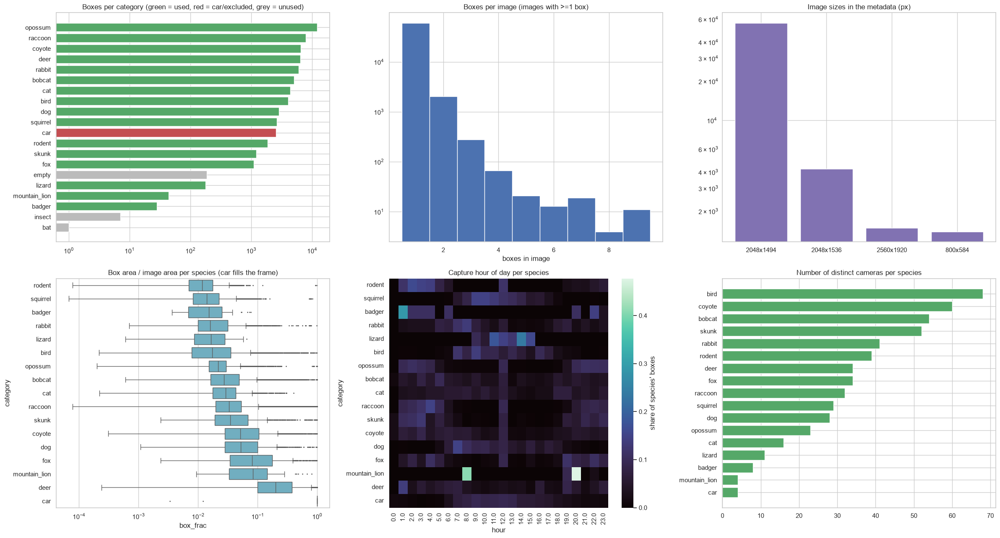

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(24, 13))
cc = anns.category.value_counts()
cols = ["#55a868" if c in SPECIES16 else "#c44e52" if c == "car" else "#bbbbbb" for c in cc.index]
ax[0, 0].barh(cc.index[::-1], cc.values[::-1], color=cols[::-1]); ax[0, 0].set_xscale("log")
ax[0, 0].set_title("Boxes per category (green = used, red = car/excluded, grey = unused)")
bpi = anns.groupby("image_id").size()
ax[0, 1].hist(bpi, bins=np.arange(0.5, bpi.max() + 1.5, 1), color="#4c72b0"); ax[0, 1].set_yscale("log")
ax[0, 1].set_title("Boxes per image (images with >=1 box)"); ax[0, 1].set_xlabel("boxes in image")
sz = (imgs.width.astype(str) + "x" + imgs.height.astype(str)).value_counts()
ax[0, 2].bar(sz.index, sz.values, color="#8172b2"); ax[0, 2].set_yscale("log"); ax[0, 2].set_title("Image sizes in the metadata (px)")
sp17 = anns[anns.category.isin(SPECIES)]
order = sp17.groupby("category").box_frac.median().sort_values().index
sns.boxplot(data=sp17, y="category", x="box_frac", order=order, ax=ax[1, 0], fliersize=1, color="#64b5cd")
ax[1, 0].set_xscale("log"); ax[1, 0].set_title("Box area / image area per species (car fills the frame)")
hh = pd.crosstab(sp17.category, sp17.hour, normalize="index").reindex(order)
sns.heatmap(hh, ax=ax[1, 1], cmap="mako", cbar_kws=dict(label="share of species' boxes")); ax[1, 1].set_title("Capture hour of day per species")
lc = sp17.groupby("category").location.nunique().sort_values()
ax[1, 2].barh(lc.index, lc.values, color="#55a868"); ax[1, 2].set_title("Number of distinct cameras per species")
fig.tight_layout(); fig.savefig(FIG / "eda" / "eda_dataset_overview.png", dpi=150); plt.show()

## 2. Sample points (per-box sampling, up to 100 boxes per species, seed 42)
`badger` (28) and `mountain_lion` (44) have fewer than 100 *boxes*, so all of them are used (some images contribute several boxes).
The 17-class draw is reproduced exactly (the RNG stream includes `car`), then `car` is dropped, so the 16 animal species keep the **identical** samples
and `sample_id`s (the synthetic-background noise is seeded by `sample_id`) as in the earlier 17-class runs.

In [5]:
pool = (pd.DataFrame({"species": anns.category, "ann_id": anns.ann_id, "image_id": anns.image_id, "file_name": anns.file_name,
                      "x": anns.x, "y": anns.y, "w": anns.w, "h": anns.h, "json_w": anns.width, "json_h": anns.height})
        .query("species in @SPECIES").sort_values(["species", "ann_id"]).reset_index(drop=True))
rng = np.random.default_rng(SEED)
parts = []
for sp in SPECIES:                                   # alphabetical, fixed order -> deterministic
    sub = pool[pool.species == sp]
    parts.append(sub.iloc[np.sort(rng.choice(len(sub), size=min(MAX_PER_SPECIES, len(sub)), replace=False))])
sample17 = pd.concat(parts).reset_index(drop=True)
sample17.insert(0, "sample_id", range(len(sample17)))
counts17 = sample17.species.value_counts().to_dict()
assert len(sample17) == 1572 and counts17 == EXPECTED_COUNTS, counts17
ref = pd.read_csv(DATA / "sample.csv")
assert (ref.ann_id.values == sample17.ann_id.values).all(), "re-built sample differs from the earlier runs"
print("17-class sample rebuilt: 1,572 boxes - identical to data/sample.csv used by the earlier runs")

sample = sample17[sample17.species != "car"].reset_index(drop=True)
if SMOKE:
    sample = pd.concat([sample[sample.species == s].head(10) for s in ["dog", "opossum", "raccoon"]]).reset_index(drop=True)
print("animal-only samples:", len(sample), "| species:", sample.species.nunique(), "| unique images:", sample.file_name.nunique(),
      "| images used by >1 box:", int((sample.file_name.value_counts() > 1).sum()))
missing = [f for f in sample.file_name.unique() if not (IMAGES / f).exists()]
if missing:   # download the original full-resolution files from LILA's per-image Azure copy
    import importlib; fetch = importlib.import_module("07_fetch_images")
    for r in sample[sample.file_name.isin(missing)].drop_duplicates("file_name").itertuples(): fetch.fetch(r)
assert all((IMAGES / f).exists() for f in sample.file_name.unique())

17-class sample rebuilt: 1,572 boxes - identical to data/sample.csv used by the earlier runs
animal-only samples: 1472 | species: 16 | unique images: 1455 | images used by >1 box: 11


In [6]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

def img_stats(fn):
    with Image.open(IMAGES / fn) as im:
        im.draft("RGB", (320, 320))
        a = np.asarray(im.convert("RGB").resize((160, 120)), dtype=np.float32)
    return float(a.mean()), float((a.max(2) - a.min(2)).mean()), im.size

with phase("image_stats"):
    files = sample.file_name.unique().tolist()
    with ThreadPoolExecutor(8) as ex:
        st = dict(zip(files, ex.map(img_stats, files)))
sample["brightness"] = sample.file_name.map(lambda f: st[f][0])
sample["saturation"] = sample.file_name.map(lambda f: st[f][1])
sample["is_gray_ir"] = sample.saturation < 4                       # infrared/night frames are exactly grayscale
sample = sample.merge(imgs[["image_id", "location", "date_captured"]], on="image_id", how="left")
sample["hour"] = pd.to_datetime(sample.date_captured, errors="coerce").dt.hour
sample["box_frac"] = sample.w * sample.h / (sample.json_w * sample.json_h)
LEVEL_M = dict(full=1.0, loose=0.5, medium=0.25, tight=0.05, ultra_tight=0.0)
for lvl, m in LEVEL_M.items():                                      # share of the image covered by each crop level
    L, T = (sample.x - m * sample.w).clip(lower=0), (sample.y - m * sample.h).clip(lower=0)
    R, B = (sample.x + (1 + m) * sample.w).clip(upper=sample.json_w), (sample.y + (1 + m) * sample.h).clip(upper=sample.json_h)
    sample[f"cover_{lvl}"] = (R - L) * (B - T) / (sample.json_w * sample.json_h)
display(sample.groupby("species").agg(n=("sample_id", "count"), images=("file_name", "nunique"), cameras=("location", "nunique"),
        median_box_frac=("box_frac", "median"), pct_night_ir=("is_gray_ir", lambda v: 100 * v.mean()),
        pct_full_crop_is_whole_image=("cover_full", lambda v: 100 * (v > 0.99).mean())).round(2))

[image_stats] 1.7 s


,n,images,cameras,median_box_frac,pct_night_ir,pct_full_crop_is_whole_image
species,,,,,,
badger,28,26,8,0.02,71.43,0.00
bird,100,98,29,0.02,11.00,0.00
bobcat,100,100,29,0.03,56.00,7.00
cat,100,100,11,0.03,59.00,0.00
coyote,100,100,29,0.04,44.00,8.00
deer,100,100,20,0.20,63.00,35.00
dog,100,100,16,0.06,31.00,2.00
fox,100,100,24,0.09,82.00,14.00
lizard,100,100,11,0.02,0.00,0.00


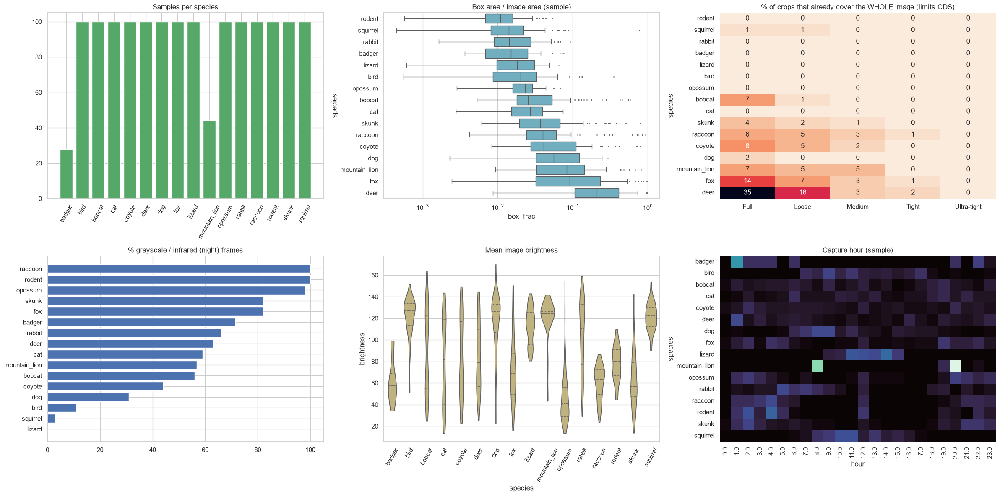

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(24, 12))
cnt = sample.species.value_counts().reindex(SPECIES16).dropna()
ax[0, 0].bar(cnt.index, cnt.values, color="#55a868"); ax[0, 0].tick_params(axis="x", rotation=60); ax[0, 0].set_title("Samples per species")
o = sample.groupby("species").box_frac.median().sort_values().index
sns.boxplot(data=sample, y="species", x="box_frac", order=o, ax=ax[0, 1], fliersize=1, color="#64b5cd"); ax[0, 1].set_xscale("log")
ax[0, 1].set_title("Box area / image area (sample)")
cov = sample.groupby("species")[[f"cover_{l}" for l in LEVELS]].apply(lambda d: 100 * (d > 0.99).mean()).reindex(o)
cov.columns = LEVEL_LABELS
sns.heatmap(cov, annot=True, fmt=".0f", cmap="rocket_r", ax=ax[0, 2], cbar=False)
ax[0, 2].set_title("% of crops that already cover the WHOLE image (limits CDS)")
gn = sample.groupby("species").is_gray_ir.mean().mul(100).sort_values()
ax[1, 0].barh(gn.index, gn.values, color="#4c72b0"); ax[1, 0].set_title("% grayscale / infrared (night) frames")
sns.violinplot(data=sample, x="species", y="brightness", ax=ax[1, 1], cut=0, color="#ccb974", inner="quartile")
ax[1, 1].tick_params(axis="x", rotation=60); ax[1, 1].set_title("Mean image brightness")
hh = pd.crosstab(sample.species, sample.hour, normalize="index")
sns.heatmap(hh, ax=ax[1, 2], cmap="mako", cbar=False); ax[1, 2].set_title("Capture hour (sample)")
fig.tight_layout(); fig.savefig(FIG / "eda" / "eda_sample_points.png", dpi=150); plt.show()

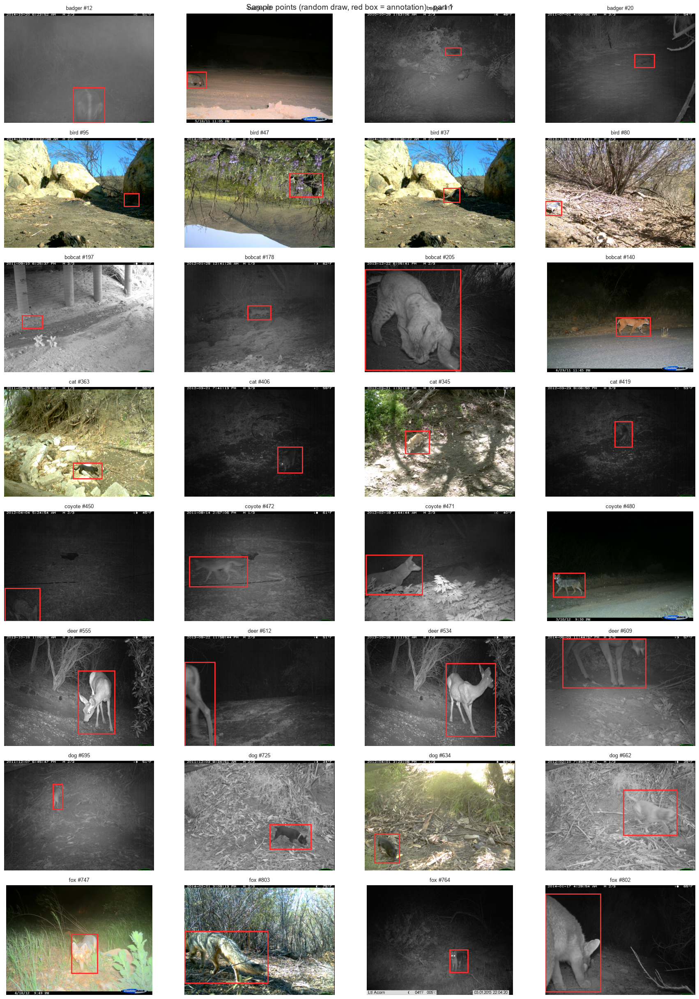

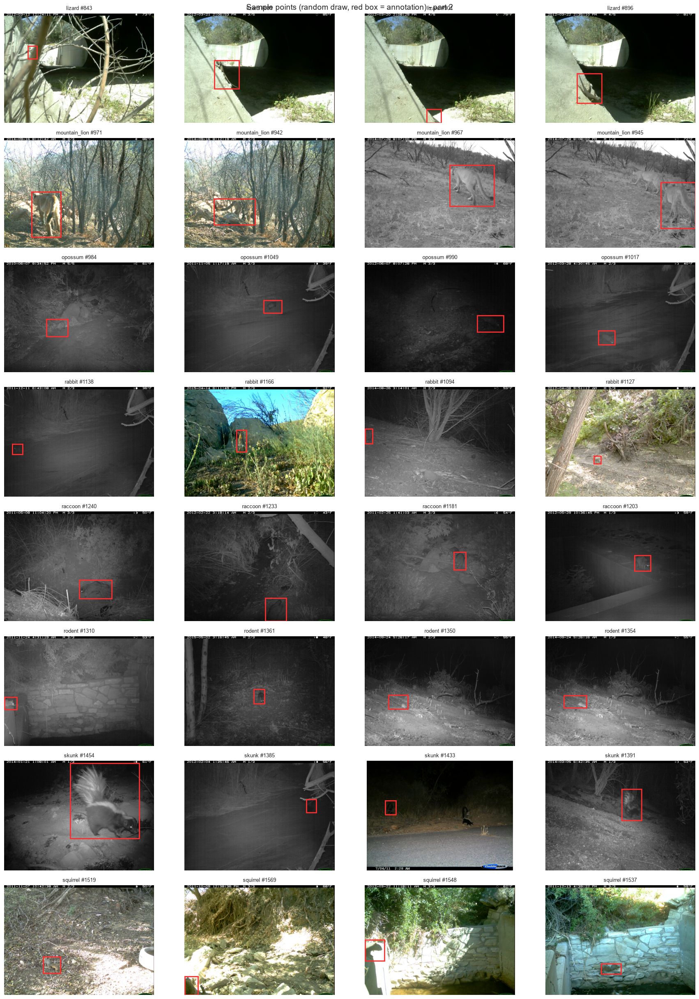

In [8]:
from imaging import load_image, scaled_box, make_variant
import matplotlib.patches as mp

def thumb(r, ax, label=True):
    with Image.open(IMAGES / r.file_name) as im:
        im.draft("RGB", (480, 360)); im = im.convert("RGB")
    s = im.width / r.json_w
    ax.imshow(im); ax.add_patch(mp.Rectangle((r.x * s, r.y * s), r.w * s, r.h * s, fill=False, ec="#ff2d2d", lw=2)); ax.axis("off")
    if label: ax.set_title(f"{r.species} #{r.sample_id}", fontsize=9)

rs = np.random.default_rng(SEED)
for gi, grp in enumerate([SPECIES16[:8], SPECIES16[8:]]):
    fig, axes = plt.subplots(len(grp), 4, figsize=(18, 3.1 * len(grp)))
    for i, sp in enumerate(grp):
        sub = sample[sample.species == sp]
        for j, k in enumerate(rs.choice(len(sub), size=min(4, len(sub)), replace=False)):
            thumb(sub.iloc[k], axes[i, j])
        for j in range(min(4, len(sub)), 4): axes[i, j].axis("off")
    fig.suptitle(f"Sample points (random draw, red box = annotation) - part {gi + 1}", fontsize=14)
    fig.tight_layout(); fig.savefig(FIG / "eda" / f"sample_gallery_{gi + 1}.png", dpi=110); plt.show()

## 3. Experiment conditions (what each model sees)
Exp 1: margin crops 100/50/25/5/0 % of the box size around the box. Exp 2: the animal's bounding-box content pasted at the **same position** on a synthetic
full-size background (solid colour -> Gaussian blur r=12 -> Gaussian noise std 10). Exp 3: four prompt templates on the original image.
Exp 4: the bbox region Gaussian-blurred (r=30), the habitat left intact.

,species,habitat_1,habitat_2,rationale,n_samples
0,badger,arctic,desert,required by task (burrowing woodland/grassland...,28
1,mountain_lion,arctic,desert,required by task,44
2,opossum,arctic,desert,"warm-temperate woodland species, poorly adapte...",100
3,raccoon,arctic,desert,riparian/woodland species; snow and dry sand a...,100
4,squirrel,arctic,desert,forest/tree-dependent species,100
5,bobcat,arctic,urban,solitary forest/scrub carnivore; avoids dense ...,100
6,deer,arctic,urban,task: no aquatic for deer; woodland browser,100
7,lizard,aquatic,urban,"task: no desert for lizard; ectotherm, not aqu...",100
8,bird,arctic,aquatic,"terrestrial passerine/quail-type birds, not sn...",100
9,coyote,arctic,aquatic,desert/scrub-adapted canid,100


mismatch predictions per habitat: {'arctic': 1172, 'desert': 572, 'aquatic': 900, 'urban': 300} | total per model/activation: 2944 (animal-only; 17-class design had 3,144)


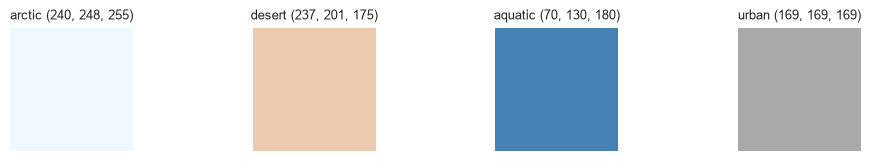

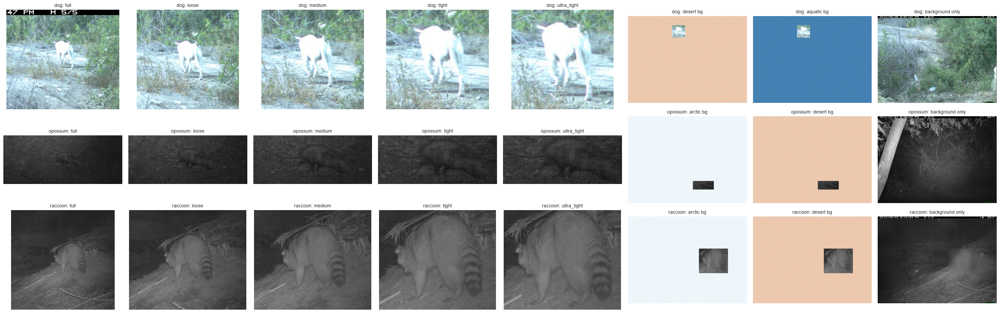

In [9]:
from habitats import HABITAT_MAP, HABITAT_COLORS, check_totals
hab_tab = pd.DataFrame([dict(species=s, habitat_1=h[0], habitat_2=h[1], rationale=h[2]) for s, h in HABITAT_MAP.items() if s != "car"])
hab_tab["n_samples"] = hab_tab.species.map(sample17.species.value_counts())
display(hab_tab)
tot = check_totals({s: int(n) for s, n in sample.species.value_counts().items()})
print("mismatch predictions per habitat:", tot, "| total per model/activation:", sum(tot.values()),
      "(animal-only; 17-class design had 3,144)")
if not SMOKE:
    assert tot == {"arctic": 1172, "desert": 572, "aquatic": 900, "urban": 300}
fig, axs = plt.subplots(1, 4, figsize=(12, 1.6))
for ax_, (h, c) in zip(axs, HABITAT_COLORS.items()):
    ax_.imshow(np.full((10, 10, 3), c, dtype=np.uint8)); ax_.set_title(f"{h} {c}", fontsize=9); ax_.axis("off")
plt.show()

row = lambda sp: sample[sample.species == sp].iloc[0]
fig, axes = plt.subplots(3, 8, figsize=(30, 9.5))
for i, sp in enumerate(["dog", "opossum", "raccoon"]):
    r = row(sp); img = load_image(r.file_name); box = scaled_box(img, r.x, r.y, r.w, r.h, r.json_w, r.json_h)
    h1, h2 = HABITAT_MAP[sp][:2]
    vs = [(f"crop_{l}", l) for l in LEVELS] + [(f"mismatch_{h1}", f"{h1} bg"), (f"mismatch_{h2}", f"{h2} bg"), ("bgonly", "background only")]
    vs = vs[:7] + [vs[7]]
    for ax_, (v, t) in zip(axes[i], vs[:8]):
        ax_.imshow(make_variant(img, box, v, int(r.sample_id))); ax_.set_title(f"{sp}: {t}", fontsize=10); ax_.axis("off")
fig.tight_layout(); fig.savefig(FIG / "eda" / "condition_gallery.png", dpi=110); plt.show()

## 4. Models and the activation switch (QuickGELU / GELU)

In [10]:
from open_clip.transformer import QuickGELU
from models import MODEL_SPECS, PROMPTS
ACTS = ["quickgelu", "gelu"]
CLASSES = SPECIES16                                   # 16 animal classes = the label set of every prompt

class SwitchAct(nn.Module):
    """Shared by all MLP blocks of one model so that all activations can be evaluated in ONE pass over the images."""
    def __init__(self):
        super().__init__(); self.mode = "quickgelu"
    def forward(self, x):
        if self.mode == "quickgelu": return x * torch.sigmoid(1.702 * x)
        if self.mode == "gelu": return F.gelu(x)
        raise ValueError(self.mode)

def load_model(label):
    spec = MODEL_SPECS[label]
    kw = {"pretrained": spec["pretrained"]} if spec["pretrained"] else {}
    if spec["quick_gelu"]: kw["force_quick_gelu"] = True        # silences open_clip's warning; the activation is replaced below anyway
    model, _, pre = open_clip.create_model_and_transforms(spec["name"], **kw)
    tok = open_clip.get_tokenizer(spec["name"])
    model.to(DEVICE).eval()
    act, n = SwitchAct(), 0
    for mod in list(model.modules()):
        for name, child in list(mod.named_children()):
            if isinstance(child, (nn.GELU, QuickGELU)):
                setattr(mod, name, act); n += 1
    assert n > 0
    return dict(model=model, pre=pre, tok=tok, act=act, n_patched=n, scale=float(model.logit_scale.exp().item()),
                params_M=round(sum(p.numel() for p in model.parameters()) / 1e6, 1), patch=model.visual.conv1.kernel_size[0])

with phase("load_models"):
    M = {lab: load_model(lab) for lab in MODEL_SPECS}
display(pd.DataFrame({lab: {k: m[k] for k in ("params_M", "patch", "n_patched", "scale")} for lab, m in M.items()}).T.rename(
    columns={"params_M": "params (M)", "patch": "patch size", "n_patched": "activation layers swapped", "scale": "logit scale"}))

[load_models] 5.9 s


,params (M),patch size,activation layers swapped,logit scale
ViT-B/32,151.3,32.0,24.0,100.0
ViT-L/14,427.6,14.0,36.0,100.0
BioCLIP,149.6,16.0,24.0,100.0


## 5. Run all experiments
Every image variant (5 crops, original, 4 synthetic-habitat sets, background-only) is generated **once** and encoded by all three models under both
activations. L2-normalised embeddings are cached per (model, activation, variant) in `data/cache/nb_animal/` (resumable; the first run computes everything).

In [11]:
from run_experiments import VariantDS, variant_table, pick_bg_only, slug, BATCH
from types import SimpleNamespace
from torch.utils.data import DataLoader
from tqdm import tqdm

bg_all = pick_bg_only(sample17)                         # the same 85 images as the 17-class run ...
bg = bg_all[bg_all.species != "car"]                    # ... minus the 5 car images -> 80
if SMOKE: bg = pick_bg_only(sample)
variants = variant_table(sample, bg)
n_mm = sum(len(d) for k, d in variants.items() if k.startswith("mismatch_"))
print({k: len(v) for k, v in variants.items()}, "| mismatch predictions / model / activation:", n_mm, "| bg-only n:", len(bg))
if not SMOKE: assert n_mm == 2944 and len(bg) == 80
workers = 0 if SMOKE else 6
t_exp = time.time()
for vname, df in variants.items():
    need = [(l, a) for l in M for a in ACTS if not (CACHE_NB / f"{slug(l)}__{a}__{vname}.npz").exists()]
    if not need:
        print(f"[skip] {vname} cached"); continue
    t0 = time.time()
    labs = sorted({l for l, _ in need}, key=list(M).index)
    ds = VariantDS([SimpleNamespace(**r) for r in df.to_dict("records")], vname, [M[l]["pre"] for l in labs])
    feats = {k: [] for k in need}
    for batch in tqdm(DataLoader(ds, batch_size=BATCH, num_workers=workers, pin_memory=(DEVICE == "cuda")), desc=vname, leave=False, mininterval=10):
        for lab, x in zip(labs, batch):
            x = x.to(DEVICE, non_blocking=True)
            for a in [a for l, a in need if l == lab]:
                M[lab]["act"].mode = a
                with torch.no_grad():
                    f = M[lab]["model"].encode_image(x)
                feats[(lab, a)].append((f / f.norm(dim=-1, keepdim=True)).float().cpu().numpy())
    for (lab, a), v in feats.items():
        np.savez(CACHE_NB / f"{slug(lab)}__{a}__{vname}.npz", sample_ids=df.sample_id.to_numpy(), feats=np.concatenate(v))
    TIMINGS[f"embed_{vname}_s"] = round(time.time() - t0, 1)
    print(f"[done] {vname}: n={len(df)} in {TIMINGS[f'embed_{vname}_s']} s", flush=True)
TIMINGS["experiments_embedding_total_s"] = round(time.time() - t_exp, 1)
print("total embedding time:", TIMINGS["experiments_embedding_total_s"], "s")

{'crop_full': 1472, 'crop_loose': 1472, 'crop_medium': 1472, 'crop_tight': 1472, 'crop_ultra_tight': 1472, 'orig': 1472, 'mismatch_arctic': 1172, 'mismatch_desert': 572, 'mismatch_aquatic': 900, 'mismatch_urban': 300, 'bgonly': 80} | mismatch predictions / model / activation: 2944 | bg-only n: 80


crop_full:   0%|          | 0/23 [00:00<?, ?it/s]

crop_full:   4%|▍         | 1/23 [00:22<08:17, 22.63s/it]

crop_full:  39%|███▉      | 9/23 [00:33<00:43,  3.12s/it]

crop_full:  74%|███████▍  | 17/23 [00:45<00:12,  2.14s/it]

[done] crop_full: n=1472 in 54.4 s


... (44 outputs left out)

bgonly:   0%|          | 0/2 [00:00<?, ?it/s]

bgonly:  50%|█████     | 1/2 [00:10<00:10, 10.17s/it]

[done] bgonly: n=80 in 11.5 s


total embedding time: 596.2 s


In [12]:
# sanity: the switchable activations must reproduce the embeddings of the earlier independent runs (forced-QuickGELU / plain-GELU builds)
checks = {}
for (lab, a), folder in {("ViT-B/32", "quickgelu"): "full", ("ViT-L/14", "quickgelu"): "full", ("BioCLIP", "gelu"): "full",
                         ("ViT-B/32", "gelu"): "plain_gelu", ("ViT-L/14", "gelu"): "plain_gelu"}.items():
    fo = CACHE / folder / f"{slug(lab)}__crop_full.npz"
    if not fo.exists(): continue
    zo, zn = np.load(fo), np.load(CACHE_NB / f"{slug(lab)}__{a}__crop_full.npz")
    pos = {int(s): i for i, s in enumerate(zo["sample_ids"])}
    checks[f"{lab} / {a}"] = float(np.abs(zo["feats"][[pos[int(s)] for s in zn["sample_ids"]]] - zn["feats"]).max())
print("max |difference| vs earlier runs:", checks or "earlier caches not present")
assert all(v < 1e-4 for v in checks.values())

max |difference| vs earlier runs: {'ViT-B/32 / quickgelu': 0.0, 'ViT-L/14 / quickgelu': 1.1920928955078125e-07, 'BioCLIP / gelu': 0.0, 'ViT-B/32 / gelu': 0.0, 'ViT-L/14 / gelu': 1.1920928955078125e-07}


In [13]:
@torch.no_grad()
def text_emb(m, mode, prompt):
    m["act"].mode = mode
    f = m["model"].encode_text(m["tok"]([PROMPTS[prompt].format(class_name(s)) for s in CLASSES]).to(DEVICE))
    return f / f.norm(dim=-1, keepdim=True)

plan = [("exp1", f"crop_{l}", l, "neutral") for l in LEVELS] + [("exp2_baseline", "orig", "original", "neutral")]
plan += [("exp3", "orig", "original", p) for p in PROMPT_KEYS] + [("exp2_mismatch", f"mismatch_{h}", h, "neutral") for h in HABS]
plan += [("exp4", "bgonly", "bg_only_blur30", "neutral")]
plan = [t for t in plan if t[1] in variants]
spec = sample.set_index("sample_id")
recs = []
with phase("predictions"):
    for lab, m in M.items():
        for a in ACTS:
            for exp, vname, cond, prompt in plan:
                z = np.load(CACHE_NB / f"{slug(lab)}__{a}__{vname}.npz")
                sims = torch.from_numpy(z["feats"]).to(DEVICE) @ text_emb(m, a, prompt).T          # cosine similarity
                conf, pred = torch.softmax(m["scale"] * sims, dim=-1).max(dim=-1)                  # softmax(logit_scale * sims)
                ids, pred_sp = z["sample_ids"], np.array(CLASSES)[pred.cpu().numpy()]
                truth = spec.loc[ids, "species"].to_numpy()
                recs.append(pd.DataFrame({"model": lab, "activation": a, "experiment": exp, "condition": cond, "prompt": prompt,
                    "habitat": cond if exp == "exp2_mismatch" else "", "sample_id": ids, "species": truth,
                    "image_path": [str(IMAGES / f) for f in spec.loc[ids, "file_name"]], "prediction": pred_sp,
                    "confidence": conf.cpu().numpy(), "correct": pred_sp == truth}))
P = pd.concat(recs, ignore_index=True)
P.to_csv(OUT / "all_predictions.csv", index=False)
print(f"{len(P):,} prediction rows saved ->", OUT / "all_predictions.csv")
print(P.groupby(["model", "activation", "experiment"]).size().unstack().to_string())

[predictions] 2.1 s


106,464 prediction rows saved -> C:\Users\PC\Desktop\Programs\wildlife_context_repro\results\notebook_animal\all_predictions.csv
experiment           exp1  exp2_baseline  exp2_mismatch  exp3  exp4
model    activation                                                
BioCLIP  gelu        7360           1472           2944  5888    80
         quickgelu   7360           1472           2944  5888    80
ViT-B/32 gelu        7360           1472           2944  5888    80
         quickgelu   7360           1472           2944  5888    80
ViT-L/14 gelu        7360           1472           2944  5888    80
         quickgelu   7360           1472           2944  5888    80


## 6. Results (animal-only, 16 classes)

In [14]:
R = {a: summarize(P[P.activation == a]) for a in ACTS}
LBL = {"quickgelu": "QuickGELU (primary)", "gelu": "GELU"}
cols = ["acc_full", "acc_ultra_tight", "CDS", "acc_baseline", "acc_mismatch", "CR", "PS", "BG_only", "conf_acc_gap_ut", "neg_cds_species"]
for a in ACTS:
    display(Markdown(f"### Summary table - {LBL[a]}  (Acc in %, CR/PS/CDS in %, BG-only random baseline = 6.25 %)"))
    display(R[a]["summary"][cols].round(1))

### Summary table - QuickGELU (primary)  (Acc in %, CR/PS/CDS in %, BG-only random baseline = 6.25 %)

,acc_full,acc_ultra_tight,CDS,acc_baseline,acc_mismatch,CR,PS,BG_only,conf_acc_gap_ut,neg_cds_species
model,,,,,,,,,,
ViT-B/32,36.8,38.2,-3.9,15.1,16.7,110.8,61.5,10.0,10.800000,8
ViT-L/14,59.2,53.9,9.1,35.9,30.5,84.9,25.8,11.2,10.400000,4
BioCLIP,45.0,31.0,31.2,28.6,12.5,43.6,49.0,13.8,37.900002,1


### Summary table - GELU  (Acc in %, CR/PS/CDS in %, BG-only random baseline = 6.25 %)

,acc_full,acc_ultra_tight,CDS,acc_baseline,acc_mismatch,CR,PS,BG_only,conf_acc_gap_ut,neg_cds_species
model,,,,,,,,,,
ViT-B/32,32.3,34.5,-6.7,14.8,15.8,106.4,44.7,5.0,8.400000,8
ViT-L/14,65.2,57.5,11.9,41.8,32.2,77.2,15.5,11.2,-0.800000,4
BioCLIP,45.5,29.6,34.9,26.2,11.8,45.2,34.4,3.8,37.799999,0


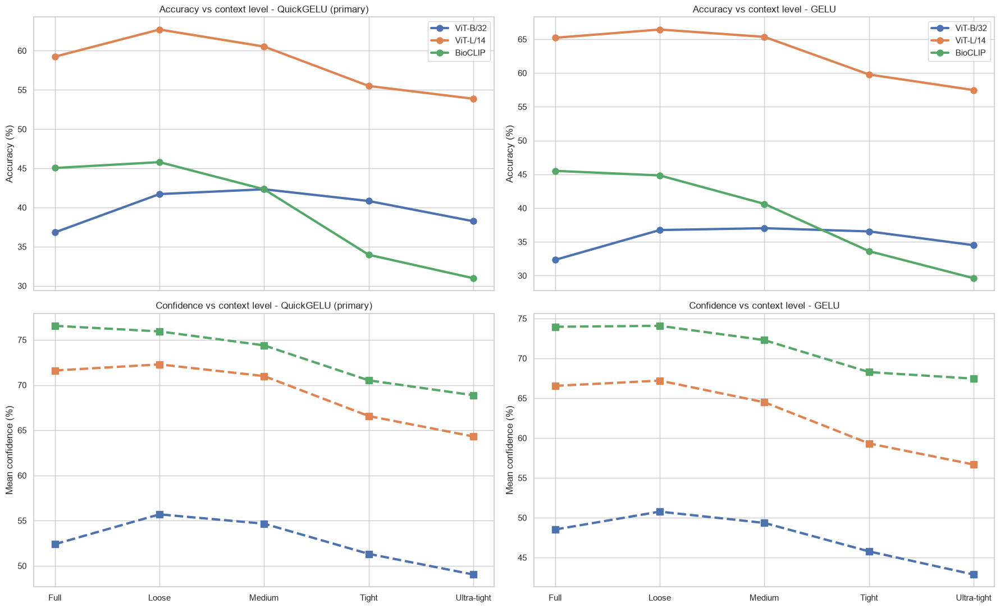

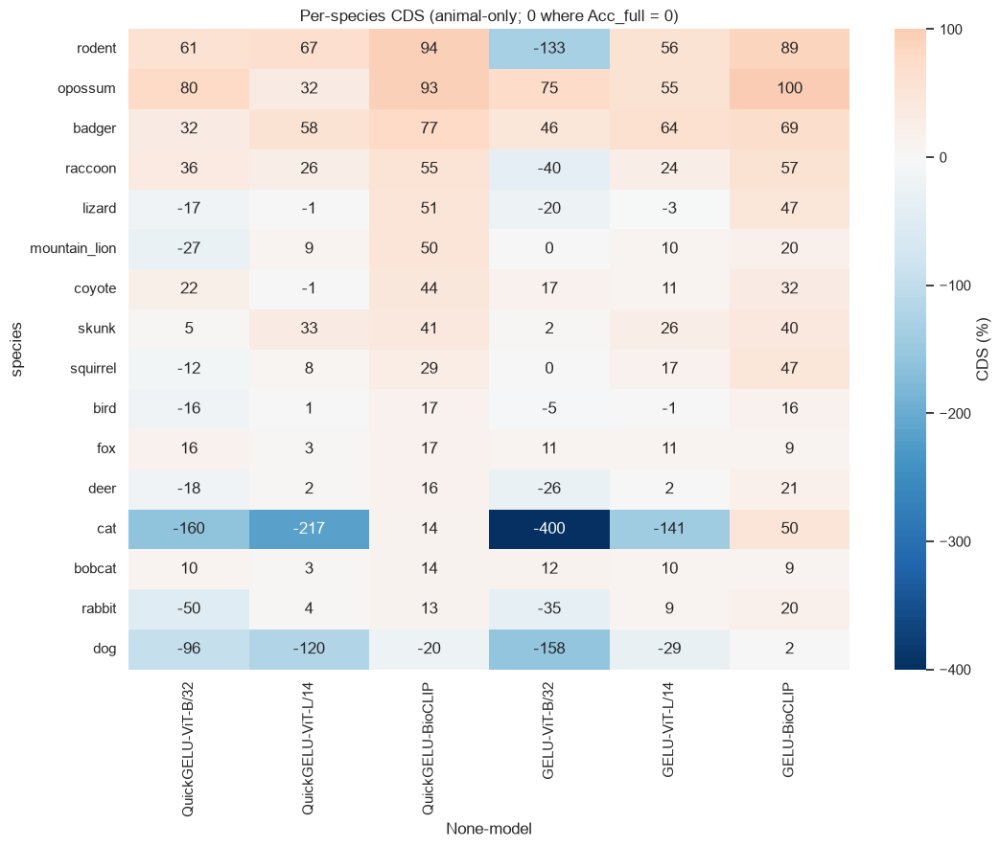

QuickGELU                      GELU                 
model          ViT-B/32 ViT-L/14 BioCLIP ViT-B/32 ViT-L/14 BioCLIP
species                                                           
rodent             60.9     66.7    93.8   -133.3     55.6    89.5
opossum            80.0     31.8    92.9     75.0     55.2   100.0
badger             32.0     57.9    77.3     46.2     64.3    68.7
raccoon            36.4     26.3    54.5    -40.0     24.1    57.4
lizard            -17.5     -1.4    51.0    -19.7     -2.8    47.3
mountain_lion     -27.3      8.8    50.0      0.0     10.0    20.0
coyote             21.9     -1.2    44.2     17.2     11.1    32.5
skunk               4.8     32.8    40.7      2.5     26.4    39.7
squirrel          -11.9      8.0    28.8      0.0     16.7    47.3
bird              -16.4      1.2    17.1     -5.3     -1.2    16.3
fox                15.8      3.3    17.0     11.1     11.1     8.7
deer              -17.6      2.5    16.1    -26.4      2.3    21.4
cat              -160.0   -216.7    14.0   -400.0   -141.2    50.0
bobcat              9.5      2.8    13.6     12.2     10.4     9.1
rabbit            -50.0      3.8    13.2    -34.8      8.8    19.7
dog               -95.8   -120.0   -20.0   -158.3    -29.4     2.1

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(18, 11), sharex=True)
for j, a in enumerate(ACTS):
    L = R[a]["levels"]
    for m in MODELS:
        q = L[L.model == m].set_index("level").loc[LEVELS]
        ax[0, j].plot(LEVEL_LABELS, q.acc, "o-", lw=3, ms=8, color=MODEL_COLORS[m], label=m)
        ax[1, j].plot(LEVEL_LABELS, q.conf, "s--", lw=3, ms=8, color=MODEL_COLORS[m], label=m)
    ax[0, j].set_title(f"Accuracy vs context level - {LBL[a]}"); ax[1, j].set_title(f"Confidence vs context level - {LBL[a]}")
    ax[0, j].set_ylabel("Accuracy (%)"); ax[1, j].set_ylabel("Mean confidence (%)"); ax[0, j].legend()
fig.tight_layout(); fig.savefig(FIG / "levels_accuracy_confidence.png", dpi=150); plt.show()

sp = {a: R[a]["species"].pivot(index="species", columns="model", values="CDS")[MODELS] for a in ACTS}
allsp = pd.concat({LBL[a].split()[0]: sp[a] for a in ACTS}, axis=1).sort_values(("QuickGELU", "BioCLIP"), ascending=False)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(allsp, annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=ax, cbar_kws=dict(label="CDS (%)"))
ax.set_title("Per-species CDS (animal-only; 0 where Acc_full = 0)"); fig.tight_layout()
fig.savefig(FIG / "per_species_cds_heatmap.png", dpi=150); plt.show()
display(allsp.round(1))

In [16]:
for a in ACTS:
    display(Markdown(f"### Per-habitat mismatch accuracy - {LBL[a]}"))
    h = R[a]["habitat"]; display(h.assign(cell=lambda d: d.correct.astype(str) + "/" + d.total.astype(str) + " (" + d.acc.round(1).astype(str) + "%)")
                                  .pivot(index="model", columns="habitat", values="cell").reindex(columns=HABS))
    display(Markdown(f"### Prompt accuracy - {LBL[a]}"))
    pt = R[a]["prompts"].pivot(index="model", columns="prompt", values="acc")[PROMPT_KEYS]
    pt["PS"] = R[a]["summary"].PS; display(pt.round(1))
d = pd.concat({LBL[a].split()[0]: R[a]["summary"][["acc_full", "acc_ultra_tight", "CDS", "CR", "PS", "BG_only"]] for a in ACTS}, axis=1)
display(Markdown("### QuickGELU vs GELU side by side")); display(d.round(1))

### Per-habitat mismatch accuracy - QuickGELU (primary)

habitat,arctic,desert,aquatic,urban
model,,,,
BioCLIP,134/1172 (11.4%),45/572 (7.9%),132/900 (14.7%),56/300 (18.7%)
ViT-B/32,198/1172 (16.9%),71/572 (12.4%),154/900 (17.1%),69/300 (23.0%)
ViT-L/14,362/1172 (30.9%),127/572 (22.2%),286/900 (31.8%),122/300 (40.7%)


### Prompt accuracy - QuickGELU (primary)

prompt,neutral,habitat,wildlife,scientific,PS
model,,,,,
BioCLIP,28.6,18.4,18.0,21.5,49.0
ViT-B/32,15.1,17.3,26.6,16.1,61.5
ViT-L/14,35.9,44.1,45.2,34.9,25.8


### Per-habitat mismatch accuracy - GELU

habitat,arctic,desert,aquatic,urban
model,,,,
BioCLIP,122/1172 (10.4%),38/572 (6.6%),121/900 (13.4%),67/300 (22.3%)
ViT-B/32,203/1172 (17.3%),37/572 (6.5%),152/900 (16.9%),72/300 (24.0%)
ViT-L/14,343/1172 (29.3%),165/572 (28.8%),329/900 (36.6%),112/300 (37.3%)


### Prompt accuracy - GELU

prompt,neutral,habitat,wildlife,scientific,PS
model,,,,,
BioCLIP,26.2,18.8,20.5,19.8,34.4
ViT-B/32,14.8,19.1,22.9,15.5,44.7
ViT-L/14,41.8,45.4,45.7,39.1,15.5


### QuickGELU vs GELU side by side

QuickGELU                                                GELU  \
          acc_full acc_ultra_tight   CDS     CR    PS BG_only acc_full   
model                                                                    
ViT-B/32      36.8            38.2  -3.9  110.8  61.5    10.0     32.3   
ViT-L/14      59.2            53.9   9.1   84.9  25.8    11.2     65.2   
BioCLIP       45.0            31.0  31.2   43.6  49.0    13.8     45.5   

                                                     
         acc_ultra_tight   CDS     CR    PS BG_only  
model                                                
ViT-B/32            34.5  -6.7  106.4  44.7     5.0  
ViT-L/14            57.5  11.9   77.2  15.5    11.2  
BioCLIP             29.6  34.9   45.2  34.4     3.8

In [17]:
# benchmark vs the paper (17-class numbers: reference only, the paper's set includes `car`)
rows = []
for a in ACTS:
    s = R[a]["summary"]
    for m in MODELS:
        t = PV.TARGETS[m]
        for k, kk in [("acc_full", "acc_full"), ("acc_ultra_tight", "acc_ultra_tight"), ("CDS", "CDS"), ("CR", "CR"), ("PS", "PS"), ("BG", "BG_only")]:
            rows.append(dict(activation=a, model=m, metric=k, paper_17class=t[k], ours_16class=round(s.loc[m, kk], 1),
                             diff_pp=round(s.loc[m, kk] - t[k], 1)))
bench = pd.DataFrame(rows)
bw = bench.pivot_table(index=["model", "metric"], columns="activation", values="ours_16class")
bw.columns = [f"ours_16class_{c}" for c in bw.columns]
bw["paper_17class"] = bench.drop_duplicates(["model", "metric"]).set_index(["model", "metric"]).paper_17class.reindex(bw.index)
for a in ACTS:
    bw[f"diff_pp_{a}"] = bw[f"ours_16class_{a}"] - bw.paper_17class
display(bw.reindex(MODELS, level=0).round(1))

ours_16class_gelu  ours_16class_quickgelu  \
model    metric                                                       
ViT-B/32 BG                             5.0                    10.0   
         CDS                           -6.7                    -3.9   
         CR                           106.4                   110.8   
         PS                            44.7                    61.5   
         acc_full                      32.3                    36.8   
         acc_ultra_tight               34.5                    38.2   
ViT-L/14 BG                            11.2                    11.2   
         CDS                           11.9                     9.1   
         CR                            77.2                    84.9   
         PS                            15.5                    25.8   
         acc_full                      65.2                    59.2   
         acc_ultra_tight               57.5                    53.9   
BioCLIP  BG                             3.8                    13.8   
         CDS                           34.9                    31.2   
         CR                            45.2                    43.6   
         PS                            34.4                    49.0   
         acc_full                      45.5                    45.0   
         acc_ultra_tight               29.6                    31.0   

                          paper_17class  diff_pp_quickgelu  diff_pp_gelu  
model    metric                                                           
ViT-B/32 BG                        12.9               -2.9          -7.9  
         CDS                       -4.0                0.1          -2.7  
         CR                        86.0               24.8          20.4  
         PS                        45.7               15.8          -1.0  
         acc_full                  33.2                3.6          -0.9  
         acc_ultra_tight           34.5                3.7           0.0  
ViT-L/14 BG                        16.5               -5.3          -5.3  
         CDS                       13.4               -4.3          -1.5  
         CR                        70.0               14.9           7.2  
         PS                        25.2                0.6          -9.7  
         acc_full                  62.5               -3.3           2.7  
         acc_ultra_tight           54.1               -0.2           3.4  
BioCLIP  BG                        11.8                2.0          -8.0  
         CDS                       37.0               -5.8          -2.1  
         CR                        46.5               -2.9          -1.3  
         PS                        37.4               11.6          -3.0  
         acc_full                  40.4                4.6           5.1  
         acc_ultra_tight           25.4                5.6           4.2

## 7. Export

In [18]:
sample_out = sample.copy(); sample_out["in_exp4_background_only"] = sample_out.sample_id.isin(bg.sample_id)
sample_out.to_csv(OUT / "sample_points.csv", index=False)
cat_tab.to_csv(OUT / "eda_category_table.csv"); hab_tab.to_csv(OUT / "habitat_mapping.csv", index=False)
for a in ACTS:
    for k in ("summary", "levels", "habitat", "prompts", "species", "species_prompt"):
        R[a][k].round(4).to_csv(OUT / f"{k}_{a}.csv")
bench.to_csv(OUT / "benchmark_vs_paper.csv", index=False)
meta_out = dict(env=env, seed=SEED, smoke=SMOKE, classes=CLASSES, n_classes=len(CLASSES), random_baseline_pct=round(100 / len(CLASSES), 2),
                activations=ACTS, models=list(M), n_samples=len(sample), n_bg_only=len(bg), n_mismatch_per_model_activation=n_mm,
                sampling="per bounding box, up to 100 per species, numpy default_rng(42), car dropped after the 17-class draw",
                params={l: dict(params_M=m["params_M"], patch=m["patch"], layers_swapped=m["n_patched"]) for l, m in M.items()},
                feature_check_vs_earlier_runs=checks, timings=TIMINGS, batch_size=BATCH, hf_cache=os.environ.get("HF_HUB_CACHE", "default"))
(OUT / "run_meta.json").write_text(json.dumps(meta_out, indent=2, default=str))
print("timings (s):", json.dumps(TIMINGS, indent=1))
print(*sorted(p.name for p in OUT.iterdir()), sep="\n")

timings (s): {
 "image_stats": 1.7,
 "load_models": 5.9,
 "embed_crop_full_s": 54.4,
 "embed_crop_loose_s": 54.2,
 "embed_crop_medium_s": 54.1,
 "embed_crop_tight_s": 54.4,
 "embed_crop_ultra_tight_s": 54.1,
 "embed_orig_s": 58.5,
 "embed_mismatch_arctic_s": 80.7,
 "embed_mismatch_desert_s": 57.6,
 "embed_mismatch_aquatic_s": 73.7,
 "embed_mismatch_urban_s": 42.9,
 "embed_bgonly_s": 11.5,
 "experiments_embedding_total_s": 596.2,
 "predictions": 2.1
}
all_predictions.csv
benchmark_vs_paper.csv
eda_category_table.csv
habitat_gelu.csv
habitat_mapping.csv
habitat_quickgelu.csv
levels_gelu.csv
levels_quickgelu.csv
prompts_gelu.csv
prompts_quickgelu.csv
run_meta.json
sample_points.csv
species_gelu.csv
species_prompt_gelu.csv
species_prompt_quickgelu.csv
species_quickgelu.csv
summary_gelu.csv
summary_quickgelu.csv
